In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

## Business Questions

**Q1. Business growth: is Rohlik growing over time?**
- **Metric:** total revenue per month, CZK; YoY growth %
- **Breakdown:** month × warehouse
- **Who cares:** management / strategy

**Q2. Warehouses & categories: where does the revenue come from?**
- **Metric:** average daily revenue per warehouse, CZK (fair comparison for warehouses with different history length); revenue share by category
- **Breakdown:** warehouse × L2 category (top-10); top-10 products by revenue
- **Who cares:** category managers, regional management

**Q3. Seasonality & calendar: when do people buy more?**
- **Metric:** average daily revenue, CZK (indexed vs. warehouse average)
- **Breakdown:** month, day of week, holiday vs. normal day (incl. days before holidays)
- **Who cares:** operations / warehouse planning (staff, stock)

**Q4. Promotions: do discounts pay off?**
- **Metric:** sales uplift % = same product's sales on discount days vs. non-discount days; revenue change
- **Breakdown:** discount size bucket (0–10%, 10–20%, 20–30%, 30%+), L1/L2 category
- **Who cares:** marketing / pricing

**Q5. Availability: how much revenue is lost due to out-of-stock?**
- **Metric:** lost revenue = sales × (1 − availability) × actual_price_czk; % of potential revenue
- **Breakdown:** warehouse, L2 category, top products with the biggest losses
- **Who cares:** supply chain / purchasing

In [4]:
df = pd.read_parquet('../data/analyzed/rohlik_cleaned.parquet')
df.shape

(4007377, 22)

In [5]:
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day_of_week'] = df['date'].dt.day_name()

In [6]:
df.head()

,unique_id,date,warehouse,total_orders,sales,sell_price_main,availability,holiday_name,holiday,shops_closed,...,potential_revenue_czk,product_unique_id,name,L1_category_name_en,L2_category_name_en,L3_category_name_en,L4_category_name_en,year,month,day_of_week
0,4845,2024-03-10,Budapest_1,6436.0,16.34,646.26,1.00,No Holiday,0,0,...,563.41,2375,Croissant_35,Bakery,Bakery_L2_18,Bakery_L3_83,Bakery_L4_1,2024,3,Sunday
1,4845,2021-05-25,Budapest_1,4663.0,12.63,455.96,1.00,No Holiday,0,0,...,308.29,2375,Croissant_35,Bakery,Bakery_L2_18,Bakery_L3_83,Bakery_L4_1,2021,5,Tuesday
2,4845,2021-12-20,Budapest_1,6507.0,34.55,455.96,1.00,No Holiday,0,0,...,843.35,2375,Croissant_35,Bakery,Bakery_L2_18,Bakery_L3_83,Bakery_L4_1,2021,12,Monday
3,4845,2023-04-29,Budapest_1,5463.0,34.52,646.26,0.96,No Holiday,0,0,...,1170.86,2375,Croissant_35,Bakery,Bakery_L2_18,Bakery_L3_83,Bakery_L4_1,2023,4,Saturday
4,4845,2022-04-01,Budapest_1,5997.0,35.92,486.41,1.00,No Holiday,0,0,...,928.47,2375,Croissant_35,Bakery,Bakery_L2_18,Bakery_L3_83,Bakery_L4_1,2022,4,Friday


**Q1. Business growth: is Rohlik growing over time?**

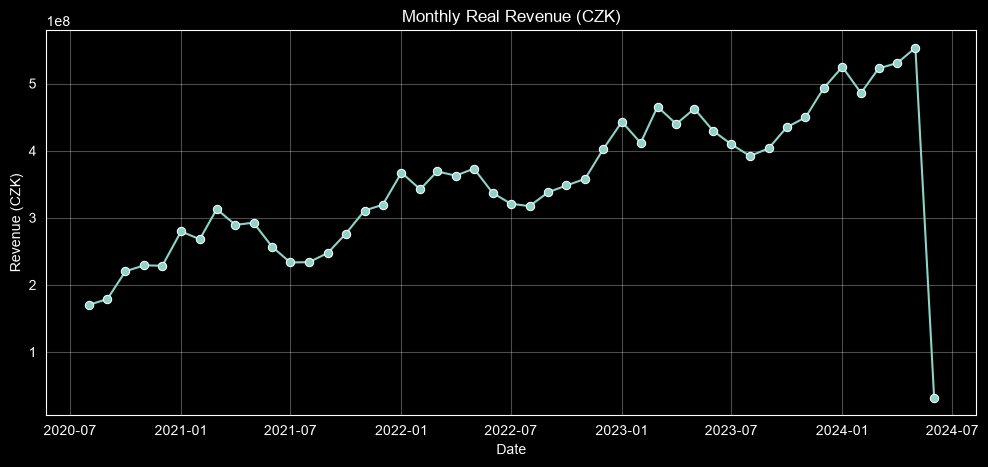

In [7]:
monthly_rev = (
    df.set_index('date')['real_revenue_czk']
    .resample('MS')
    .sum()
    .reset_index()
)
plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_rev, x='date', y='real_revenue_czk', marker='o')
plt.title('Monthly Real Revenue (CZK)')
plt.xlabel('Date')
plt.ylabel('Revenue (CZK)')
plt.grid(True, alpha=0.3)
plt.show()

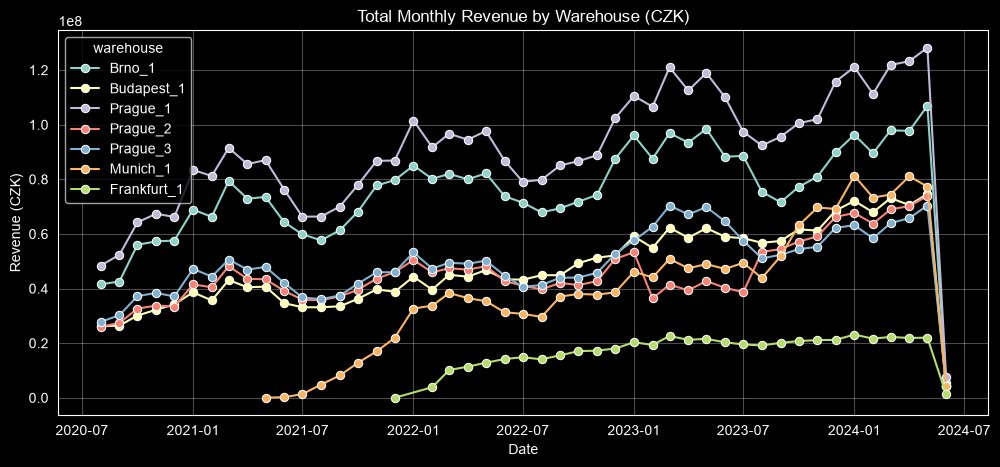

In [8]:
monthly_wh = (
    df.groupby([pd.Grouper(key='date', freq='MS'), 'warehouse'])['real_revenue_czk']
    .sum()
    .reset_index()
)

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_wh, x='date', y='real_revenue_czk', hue='warehouse', marker='o')
plt.title('Total Monthly Revenue by Warehouse (CZK)')
plt.xlabel('Date')
plt.ylabel('Revenue (CZK)')
plt.grid(True, alpha=0.3)
plt.show()

In [9]:
df.groupby(['warehouse', 'year','month'])['real_revenue_czk'].sum()

warehouse  year  month
Brno_1     2020  8        41559641.86
                 9        42561754.05
                 10       56036788.79
                 11       57261418.62
                 12       57570374.12
                             ...     
Prague_3   2024  2        58420006.76
                 3        63933367.05
                 4        65795784.20
                 5        70389070.24
                 6         4241617.83
Name: real_revenue_czk, Length: 303, dtype: float64

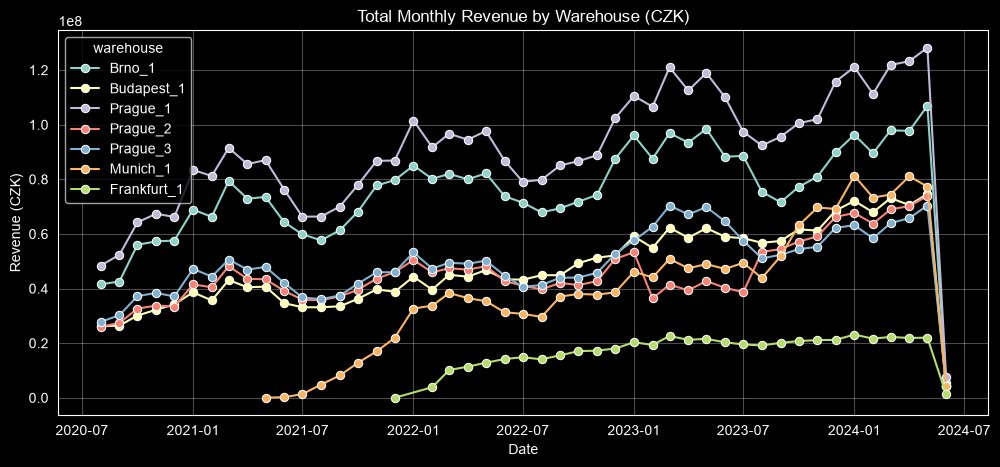

In [10]:
monthly_wh = (
    df.groupby([pd.Grouper(key='date', freq='MS'), 'warehouse'])['real_revenue_czk']
    .sum()
    .reset_index()
)

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_wh, x='date', y='real_revenue_czk', hue='warehouse', marker='o')
plt.title('Total Monthly Revenue by Warehouse (CZK)')
plt.xlabel('Date')
plt.ylabel('Revenue (CZK)')
plt.grid(True, alpha=0.3)
plt.show()